# Ideal Rankine Reheat Cycle - Heat Efficiency, η (理想ランキンサイクルの熱効率・再熱サイクル)

The **reheat cycle** modifies the basic Rankine cycle to avoid excessive moisture at the turbine exit (which erodes turbine blades) and to raise efficiency: the steam is expanded partway through a high-pressure (HP) turbine, sent back to the boiler and reheated at constant pressure, then expanded the rest of the way through a low-pressure (LP) turbine.

| State | Process |
|---|---|
| 1 → 2 | Pump: isentropic compression, $p_1 \to p_2$ |
| 2 → 3 | Boiler: heat addition at $p_2$ up to $T_3$ |
| 3 → 4 | HP turbine: isentropic expansion, $p_2 \to p_{reheat}$ |
| 4 → 5 | Reheater: heat addition at $p_{reheat}$ up to $T_5$ |
| 5 → 6 | LP turbine: isentropic expansion, $p_{reheat} \to p_1$ |
| 6 → 1 | Condenser: heat rejection at $p_1$ |

$$q_{in} = (h_3-h_2) + (h_5-h_4) \qquad w_{net} = (h_3-h_4)+(h_5-h_6)-(h_2-h_1) \qquad \eta_{th} = \frac{w_{net}}{q_{in}}$$

This notebook extends [rankine_cycle.ipynb](https://github.com/aimanamri/mechanicalEngineering/blob/main/rankine_cycle.ipynb) with the reheat stage.

Reference: [Wikipedia - Rankine cycle (reheat)](https://en.wikipedia.org/wiki/Rankine_cycle#Reheat)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyromat as pm

pm.config['unit_pressure'] = 'MPa'   # SI-derived pressure unit throughout (PYroMat defaults to bar)
water = pm.get('mp.H2O')             # remaining PYroMat unit defaults: K, kJ/kg, kJ/kg-K

class RankineReheatCycle:
    # Ideal (no losses) Rankine cycle with a single reheat stage.

    def __init__(self, p_boiler, T_boiler, p_reheat, T_reheat, p_condenser):
        # INPUT INITIAL INFORMATION
        #   p_boiler    : boiler (HP turbine inlet) pressure [MPa]
        #   T_boiler    : HP turbine inlet temperature [K]
        #   p_reheat    : reheat pressure = HP turbine exit / LP turbine inlet pressure [MPa]
        #   T_reheat    : LP turbine inlet temperature after reheat [K]
        #   p_condenser : condenser pressure [MPa]
        self.p2 = p_boiler
        self.T3 = T_boiler
        self.p_rh = p_reheat
        self.T5 = T_reheat
        self.p1 = p_condenser
        self._solve()

    def _solve(self):
        # state 1 : saturated liquid leaving the condenser
        hf1, hg1 = water.hs(p=self.p1)
        sf1, sg1 = water.ss(p=self.p1)
        vf1, vg1 = water.vs(p=self.p1)
        self.h1, self.s1, self.v1 = hf1[0], sf1[0], vf1[0]
        self.hf1, self.hg1 = hf1[0], hg1[0]

        # state 2 : pump exit (isentropic, incompressible liquid -> w_pump = v*Δp)
        self.w_pump = self.v1*(self.p2-self.p1)*1000   # MPa*m3/kg -> kJ/kg (1 MPa*m3 = 1000 kJ)
        self.h2 = self.h1 + self.w_pump

        # state 3 : boiler exit / HP turbine inlet
        self.h3 = water.h(T=self.T3, p=self.p2).item()
        self.s3 = water.s(T=self.T3, p=self.p2).item()

        # state 4 : HP turbine exit (isentropic expansion to reheat pressure)
        T4, x4 = water.T_s(s=self.s3, p=self.p_rh, quality=True)
        self.T4, self.x4 = T4[0], x4[0]
        if self.x4 >= 0:
            hf_rh, hg_rh = water.hs(p=self.p_rh)
            self.h4 = hf_rh[0] + self.x4*(hg_rh[0]-hf_rh[0])
        else:
            self.h4 = water.h(T=self.T4, p=self.p_rh).item()

        # state 5 : reheater exit / LP turbine inlet
        self.h5 = water.h(T=self.T5, p=self.p_rh).item()
        self.s5 = water.s(T=self.T5, p=self.p_rh).item()

        # state 6 : LP turbine exit (isentropic expansion to condenser pressure)
        T6, x6 = water.T_s(s=self.s5, p=self.p1, quality=True)
        self.T6, self.x6 = T6[0], x6[0]
        if self.x6 >= 0:
            self.h6 = self.hf1 + self.x6*(self.hg1-self.hf1)
        else:
            self.h6 = water.h(T=self.T6, p=self.p1).item()

        # energy balance
        self.q_in = (self.h3-self.h2) + (self.h5-self.h4)
        self.q_out = self.h6-self.h1
        self.w_turbine = (self.h3-self.h4) + (self.h5-self.h6)
        self.w_net = self.w_turbine - self.w_pump
        self.eta = self.w_net/self.q_in

    def summary(self):
        print(f"State 1 (pump inlet)      : h1={self.h1:8.2f} kJ/kg")
        print(f"State 2 (boiler inlet)    : h2={self.h2:8.2f} kJ/kg  (w_pump={self.w_pump:.2f} kJ/kg)")
        print(f"State 3 (HP turbine in)   : h3={self.h3:8.2f} kJ/kg, s3={self.s3:.4f} kJ/kg-K")
        print(f"State 4 (HP turbine out)  : h4={self.h4:8.2f} kJ/kg")
        print(f"State 5 (LP turbine in)   : h5={self.h5:8.2f} kJ/kg, s5={self.s5:.4f} kJ/kg-K")
        print(f"State 6 (LP turbine out)  : h6={self.h6:8.2f} kJ/kg  (quality x6={self.x6:.4f})")
        print()
        print(f"q_in      = {self.q_in:8.2f} kJ/kg")
        print(f"q_out     = {self.q_out:8.2f} kJ/kg")
        print(f"w_turbine = {self.w_turbine:8.2f} kJ/kg")
        print(f"w_pump    = {self.w_pump:8.2f} kJ/kg")
        print(f"w_net     = {self.w_net:8.2f} kJ/kg")
        print(f"eta_th    = {self.eta*100:.2f} %")

### Sample: classic textbook case
Boiler at 15 MPa / 600°C, reheat at 4 MPa back up to 600°C, condenser at 10 kPa (0.01 MPa) - another widely used worked example (Cengel & Boles), giving η_th ≈ 45.0% and turbine-exit quality x6 ≈ 0.895 (much drier than the non-reheat case, which was the point of adding reheat).

In [2]:
cycle = RankineReheatCycle(p_boiler=15, T_boiler=600+273.15,
                            p_reheat=4, T_reheat=600+273.15,
                            p_condenser=0.01)
cycle.summary()

State 1 (pump inlet)      : h1=  191.79 kJ/kg
State 2 (boiler inlet)    : h2=  206.94 kJ/kg  (w_pump=15.14 kJ/kg)
State 3 (HP turbine in)   : h3= 3583.17 kJ/kg, s3=6.6797 kJ/kg-K
State 4 (HP turbine out)  : h4= 3153.91 kJ/kg
State 5 (LP turbine in)   : h5= 3674.91 kJ/kg, s5=7.3706 kJ/kg-K
State 6 (LP turbine out)  : h6= 2335.64 kJ/kg  (quality x6=0.8962)

q_in      =  3897.23 kJ/kg
q_out     =  2143.85 kJ/kg
w_turbine =  1768.53 kJ/kg
w_pump    =    15.14 kJ/kg
w_net     =  1753.38 kJ/kg
eta_th    = 44.99 %


In [3]:
from rich.console import Console
from rich.table import Table

console = Console()

states = Table(title="Reheat cycle state points")
states.add_column("State"); states.add_column("h [kJ/kg]", justify="right"); states.add_column("Note")
states.add_row("1 (pump inlet)",     f"{cycle.h1:.2f}", "sat. liquid @ condenser p")
states.add_row("2 (boiler inlet)",   f"{cycle.h2:.2f}", f"w_pump = {cycle.w_pump:.2f} kJ/kg")
states.add_row("3 (HP turbine in)",  f"{cycle.h3:.2f}", "boiler exit")
states.add_row("4 (HP turbine out)", f"{cycle.h4:.2f}", "reheat pressure")
states.add_row("5 (LP turbine in)",  f"{cycle.h5:.2f}", "reheater exit")
states.add_row("6 (LP turbine out)", f"{cycle.h6:.2f}", f"quality x6 = {cycle.x6:.3f}")
console.print(states)

results = Table(title="Cycle performance")
results.add_column("Quantity"); results.add_column("Value", justify="right")
for name, val, unit in [("q_in", cycle.q_in, "kJ/kg"), ("q_out", cycle.q_out, "kJ/kg"),
                         ("w_turbine", cycle.w_turbine, "kJ/kg"), ("w_pump", cycle.w_pump, "kJ/kg"),
                         ("w_net", cycle.w_net, "kJ/kg")]:
    results.add_row(name, f"{val:.2f} {unit}")
results.add_row("eta_th", f"{cycle.eta*100:.2f} %", style="bold green")
console.print(results)

                 Reheat cycle state points                  
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ State              ┃       h ┃ Note                      ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 1 (pump inlet)     │  191.79 │ sat. liquid @ condenser p │
│ 2 (boiler inlet)   │  206.94 │ w_pump = 15.14 kJ/kg      │
│ 3 (HP turbine in)  │ 3583.17 │ boiler exit               │
│ 4 (HP turbine out) │ 3153.91 │ reheat pressure           │
│ 5 (LP turbine in)  │ 3674.91 │ reheater exit             │
│ 6 (LP turbine out) │ 2335.64 │ quality x6 = 0.896        │
└────────────────────┴─────────┴───────────────────────────┘

      Cycle performance      
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Quantity  ┃         Value ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ q_in      │ 3897.23 kJ/kg │
│ q_out     │ 2143.85 kJ/kg │
│ w_turbine │ 1768.53 kJ/kg │
│ w_pump    │   15.14 kJ/kg │
│ w_net     │ 1753.38 kJ/kg │
│ eta_th    │       44.99 % │
└───────────┴───────────────┘

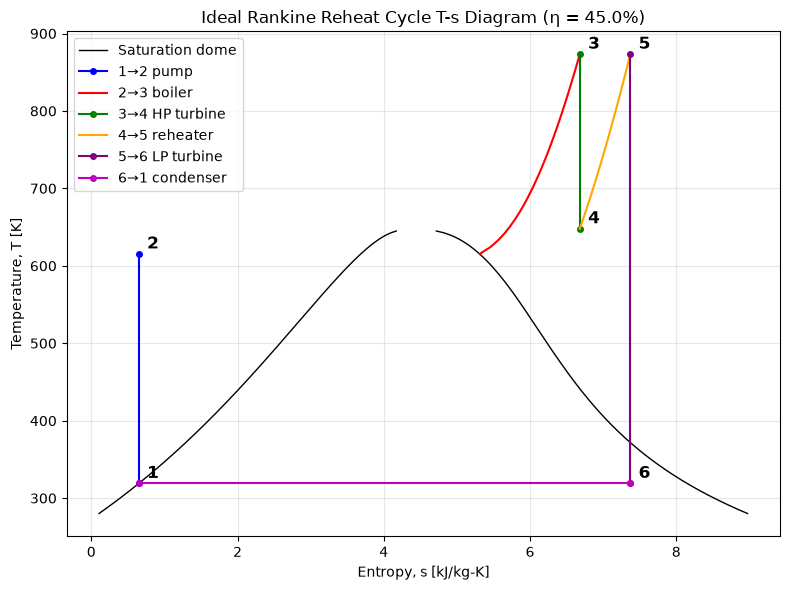

In [4]:
# T-s diagram with saturation dome
p_dome = np.geomspace(0.001, 21.5, 400)
Tsat = water.Ts(p=p_dome)
sf_dome, sg_dome = water.ss(p=p_dome)

fig, ax = plt.subplots(figsize=(8,6))
ax.plot(sf_dome, Tsat, 'k-', lw=1)
ax.plot(sg_dome, Tsat, 'k-', lw=1, label='Saturation dome')

T1sat, T2sat, Trhsat = water.Ts(p=cycle.p1)[0], water.Ts(p=cycle.p2)[0], water.Ts(p=cycle.p_rh)[0]

T23 = np.linspace(T2sat, cycle.T3, 30); s23 = water.s(T=T23, p=cycle.p2)
T45 = np.linspace(cycle.T4, cycle.T5, 30); s45 = water.s(T=T45, p=cycle.p_rh)

ax.plot([cycle.s1, cycle.s1], [T1sat, T2sat], 'b-o', ms=4, label='1→2 pump')
ax.plot(s23, T23, 'r-', label='2→3 boiler')
ax.plot([cycle.s3, cycle.s3], [cycle.T3, cycle.T4], 'g-o', ms=4, label='3→4 HP turbine')
ax.plot(s45, T45, 'orange', label='4→5 reheater')
ax.plot([cycle.s5, cycle.s5], [cycle.T5, cycle.T6], 'purple', marker='o', ms=4, label='5→6 LP turbine')
ax.plot([cycle.s5, cycle.s1], [cycle.T6, T1sat], 'm-o', ms=4, label='6→1 condenser')

pts = [('1',cycle.s1,T1sat), ('2',cycle.s1,T2sat), ('3',cycle.s3,cycle.T3),
       ('4',cycle.s3,cycle.T4), ('5',cycle.s5,cycle.T5), ('6',cycle.s5,cycle.T6)]
for lbl, s, T in pts:
    ax.annotate(lbl, (s,T), textcoords="offset points", xytext=(6,4), fontsize=12, fontweight='bold')

ax.set_xlabel('Entropy, s [kJ/kg-K]')
ax.set_ylabel('Temperature, T [K]')
ax.set_title(f'Ideal Rankine Reheat Cycle T-s Diagram (η = {cycle.eta*100:.1f}%)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Reheat vs. no reheat, same boiler/condenser conditions
Same $p_2$, $T_3$, $p_1$ as the reheat case above, but reheated back to the same temperature at different reheat pressures - shows why reheat is used: it dries out the LP turbine exhaust (raises $x$) with only a modest efficiency change, and there is a reheat pressure that (locally) maximizes efficiency.

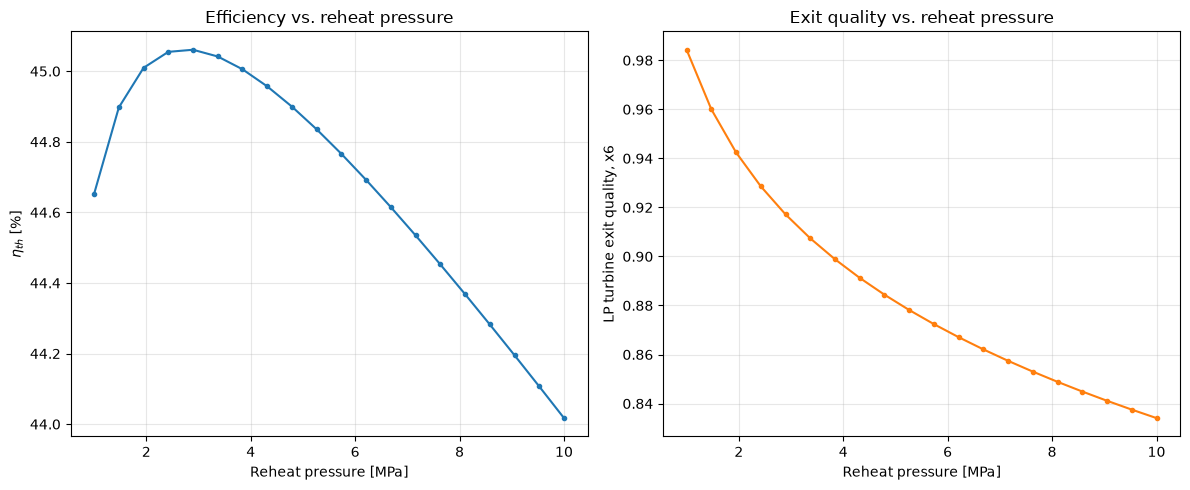

In [5]:
p_reheat_range = np.linspace(1, 10, 20)
etas, x6s = [], []
for p_rh in p_reheat_range:
    c = RankineReheatCycle(p_boiler=15, T_boiler=600+273.15,
                            p_reheat=p_rh, T_reheat=600+273.15, p_condenser=0.01)
    etas.append(c.eta*100)
    x6s.append(c.x6)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))
ax1.plot(p_reheat_range, etas, marker='.')
ax1.set_xlabel('Reheat pressure [MPa]'); ax1.set_ylabel(r'$\eta_{th}$ [%]')
ax1.set_title('Efficiency vs. reheat pressure'); ax1.grid(alpha=0.3)

ax2.plot(p_reheat_range, x6s, marker='.', color='C1')
ax2.set_xlabel('Reheat pressure [MPa]'); ax2.set_ylabel('LP turbine exit quality, x6')
ax2.set_title('Exit quality vs. reheat pressure'); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Reference :
1. [Wikipedia - Rankine cycle (reheat)](https://en.wikipedia.org/wiki/Rankine_cycle#Reheat)
2. [PYroMat documentation](https://pyromat.org/)